# H04 — In class: the real noise of Virgo

> **References**
>
> (Welch 1967), (LIGO Scientific and Virgo Collaborations 2020)

## What we do here

Lecture 11 ended with real Virgo data. In this demonstration we measure its noise, in five steps. All the code is written out: we run it cell by cell and look at what each step gives.

**The data.**
- 32 s of strain from Virgo (V1) in the third observing run, sampled at 4096 Hz.
- It is the record around the event GW190814. The signal-to-noise ratio of this event is very different in the three detectors. For what we do here the Virgo record is detector noise.
- The file is `labs/data/gw190814_V1.hdf5`. It comes from the Gravitational Wave Open Science Center (GWOSC, CC BY 4.0). It is read offline.

**The steps.**
1. Look at the record and at white noise with the same rms. What is different?
2. Estimate the amplitude spectral density with Welch's method, as in `H03`.
3. Find the narrow lines and ask what each one is.
4. Compare the spectrum with the published curve of Advanced Virgo and with a flat line.
5. Change the length of the segment: resolution against scatter.

> **The symbols**
>
> - **$h$** — the strain, a number without a unit; **rms** — its root mean square
> - **$f_{s}$** — the sampling frequency, 4096 Hz
> - **$S(f)$** — the one-sided power spectral density, in Hz$^{-1}$
> - **$\sqrt{S}$** — the amplitude spectral density (ASD), in Hz$^{-1/2}$: the sensitivity curve of lecture 11
> - **$T_{\mathrm{seg}}$** — the length of one segment of Welch's method, in s; the frequency resolution is $1/T_{\mathrm{seg}}$
> - **$K$** — the number of segments that are averaged

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import h5py
import sys, os

# the course root holds gwcourse_palette.py; find it from wherever we are
here = os.path.abspath('.')
while not os.path.exists(os.path.join(here, 'gwcourse_palette.py')):
    if os.path.dirname(here) == here:
        raise FileNotFoundError('gwcourse_palette.py not found: open the notebook from the course folder')
    here = os.path.dirname(here)
sys.path.insert(0, here)

from gwcourse_palette import P, apply_style
apply_style()

# the cached data: the Virgo strain and the published curve of Advanced Virgo; nothing is fetched
DATA = os.path.join(here, 'labs', 'data', 'gw190814_V1.hdf5')
SENS = os.path.join(here, 'labs', 'data', 'sensitivity')


def read_strain(path):
    """Read one GWOSC strain file.

    Parameters
    ----------
    path : str, the hdf5 file

    Returns
    -------
    (strain, times, fs) : strain the array h[n]; times the GPS time of each sample (s); fs the sampling frequency (Hz)
    """
    # the strain, the GPS time of the first sample and the time step
    with h5py.File(path, 'r') as f:
        strain = f['strain/Strain'][:]
        gps_start = float(f['meta/GPSstart'][()])
        dt = float(f['strain/Strain'].attrs['Xspacing'])
    fs = 1.0 / dt
    times = gps_start + np.arange(strain.size) * dt
    record = (strain, times, fs)
    return record


# the record: 32 s of Virgo strain
strain, times, fs = read_strain(DATA)
print(f"{strain.size} samples at {fs:.0f} Hz = {strain.size / fs:.0f} s, GPS {times[0]:.0f} to {times[-1]:.0f}")
print(f"rms of the strain {strain.std():.2e}")

131072 samples at 4096 Hz = 32 s, GPS 1249852241 to 1249852273
rms of the strain 1.08e-19


The workflow of this demonstration: five steps, from the record to its spectrum, its lines and the published curve.

![The record of Virgo strain, then its spectrum from Welch's method, then the narrow lines, then the comparison with the published curve and a flat line, then the length of the segment. Each box is one step.](figures/h04class_workflow.png)

> **How to use this notebook**
>
> Run the cells in order. Each step first defines its functions, then runs them. To see what a number does, change it under `# change these`, run the cell again and look at the figure. Every cell runs in a few seconds.

## Step 1 · The record and white noise

**What we do.** We draw three seconds of the Virgo record. Under it we draw white Gaussian noise with the same rms. Then we ask where the power of each record is, in frequency.

**White noise.** Every sample is a new Gaussian number. All frequencies have the same power.

**The tools.**
- `draw_real_and_white` draws the two records on the same vertical scale.
- `band_share` gives the fraction of the power of a record between two frequencies. It uses the FFT.

The parts of this step.

![The real record and a white record with the same rms are drawn on one scale. Then the share of the power in three bands is computed for each.](figures/h04class_task1_route.png)

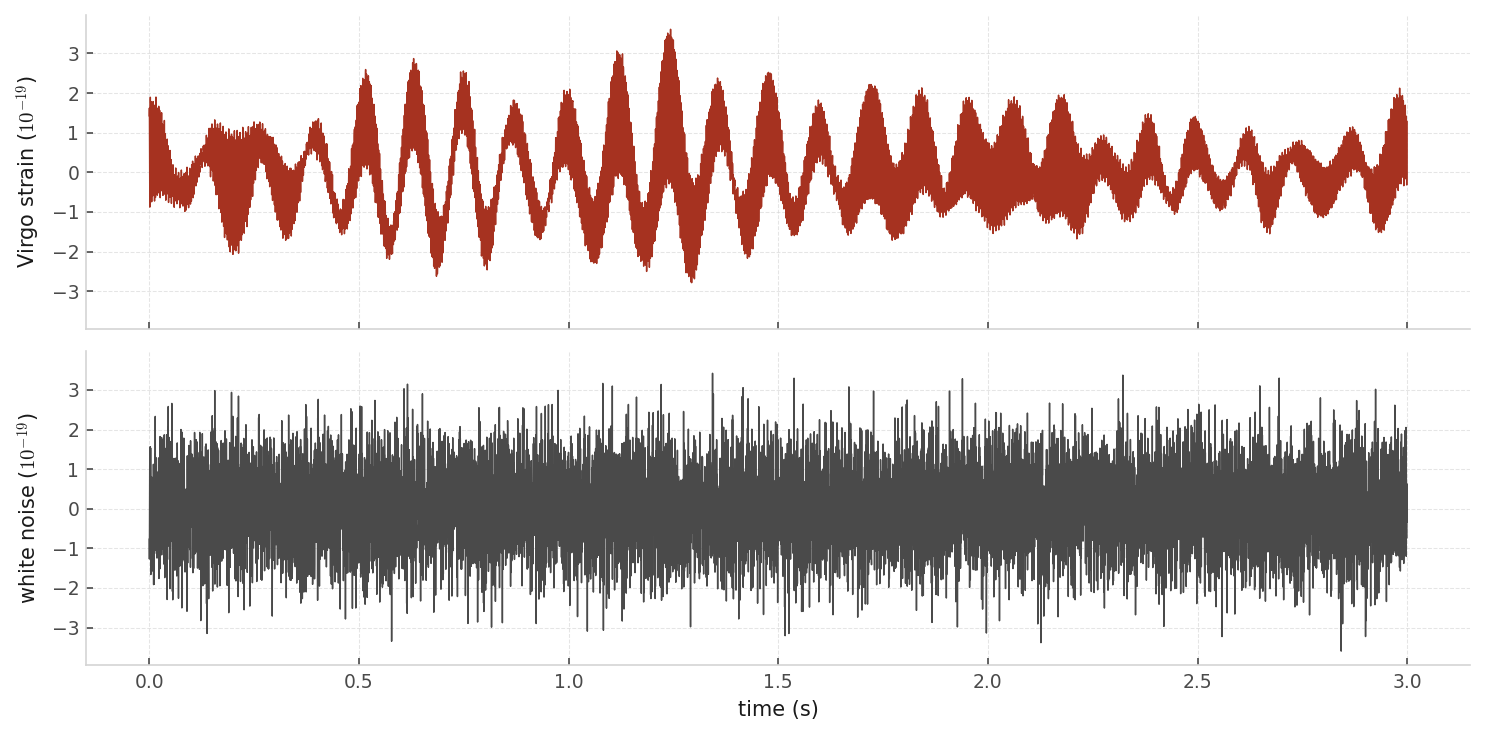

real  rms 9.59e-20   below 10 Hz 0.589   440-460 Hz 0.384   everything else 0.027
white rms 9.66e-20   below 10 Hz 0.003   440-460 Hz 0.010   everything else 0.987


In [4]:
def draw_real_and_white(t, real, white):
    """Draw a real record and a white record on the same vertical scale.

    Parameters
    ----------
    t     : array, time (s)
    real  : array, the real strain, mean removed
    white : array, white Gaussian noise with the same rms
    """
    # two panels, one scale: the real record above and the white one below
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
    ax[0].plot(t, real * 1e19, color=P['BRICK'], lw=0.7)
    ax[0].set_ylabel('Virgo strain ($10^{-19}$)')
    ax[1].plot(t, white * 1e19, color=P['GREY_DARK'], lw=0.7)
    ax[1].set(xlabel='time (s)', ylabel='white noise ($10^{-19}$)')
    plt.tight_layout()
    plt.show()


def band_share(x, fs, f_lo, f_hi):
    """Return the fraction of the power of a record between two frequencies.

    Parameters
    ----------
    x            : array, the record
    fs           : float, sampling frequency (Hz)
    f_lo, f_hi   : floats, the band (Hz); f_lo is included and f_hi is not

    Returns
    -------
    share : float between 0 and 1
    """
    # the power of each Fourier component, then the part that lies in the band
    power = np.abs(np.fft.rfft(x)) ** 2
    freq = np.fft.rfftfreq(x.size, 1 / fs)
    in_band = (freq >= f_lo) & (freq < f_hi)
    share = power[in_band].sum() / power.sum()
    return share


# change these
t_start = 1.0    # where the stretch starts (s)
length = 3.0     # how long it is (s)
seed = 5         # seed of the white noise

# the stretch of the record, with its mean removed
first = int(t_start * fs)
last = int((t_start + length) * fs)
real = strain[first:last] - strain[first:last].mean()
t = np.arange(real.size) / fs

# the rms of the real stretch and white noise with the same rms
rms = real.std()
white = np.random.default_rng(seed).normal(0.0, rms, real.size)
draw_real_and_white(t, real, white)

# the share of the power below 10 Hz, from 440 to 460 Hz and everywhere else, for each record
for name, x in (('real', real), ('white', white)):
    share_low = band_share(x, fs, 0, 10)
    share_violin = band_share(x, fs, 440, 460)
    share_rest = 1 - share_low - share_violin
    print(f"{name:5s} rms {x.std():.2e}   below 10 Hz {share_low:.3f}   440-460 Hz {share_violin:.3f}   everything else {share_rest:.3f}")

**What to look at.**
- Both records have the same rms, about $1.1\times10^{-19}$. Their range is about the same.
- The white record is a thick band of jumps. The real record is a fast ripple with a slow wave on top of it.
- The power of the white record is spread over all frequencies. The power of the real record sits in two narrow places.

**What it shows.** The white record has no structure. The real record has a slow wave and a fast ripple. Almost all its power is in two narrow places.

| record | rms | below 10 Hz | 440 to 460 Hz | everything else |
|---|---|---|---|---|
| real | $1.06\times10^{-19}$ | 0.576 | 0.394 | 0.030 |
| white | $1.06\times10^{-19}$ | 0.006 | 0.007 | 0.987 |

**Why.**
- The rms is the same by construction. The two records are still very different. The rms says how large the noise is and not how it is spread in frequency.
- The white record gives each frequency its share: 10 Hz out of 2048 Hz is half a percent. 20 Hz is one percent.
- In the real record 58 percent of the power is below 10 Hz: this is the slow wave. Another 39 percent is in a band 20 Hz wide near 450 Hz: this is the fast ripple. Its envelope beats because it is made of several close frequencies. We name them in step 3.
- So the noise of the detector is **colored**: some frequencies carry much more power than others. A flat power is the exception.
- The detector is quietest between these two places. The sensitivity curve is drawn in that region and the next steps show it.

## Step 2 · The amplitude spectral density

**What we do.** We estimate the amplitude spectral density $\sqrt{S(f)}$ of the Virgo record with Welch's method, as in `H03`. We do the same for white noise with the same rms and we draw both on log axes.

**Welch's method in `signal.welch`.**
- The record is cut into segments of `nperseg` samples. The default is a 50 percent overlap.
- Each segment is multiplied by a window: we use `'hann'`.
- The squared Fourier transforms of the segments are averaged.
- The result is one sided: the power at $-f$ is added to the power at $+f$. The function returns the frequencies and $S(f)$ in Hz$^{-1}$. The ASD is its square root.

**The function.** `draw_asd` draws one or more ASDs on log axes from `f_min_plot`.

The parts of this step.

![The record is cut into segments with a window, the squared transforms are averaged, the square root gives the ASD. The same is done for white noise.](figures/h04class_task2_route.png)

resolution 0.250 Hz, 15 segments
white noise: median ASD 2.36e-21


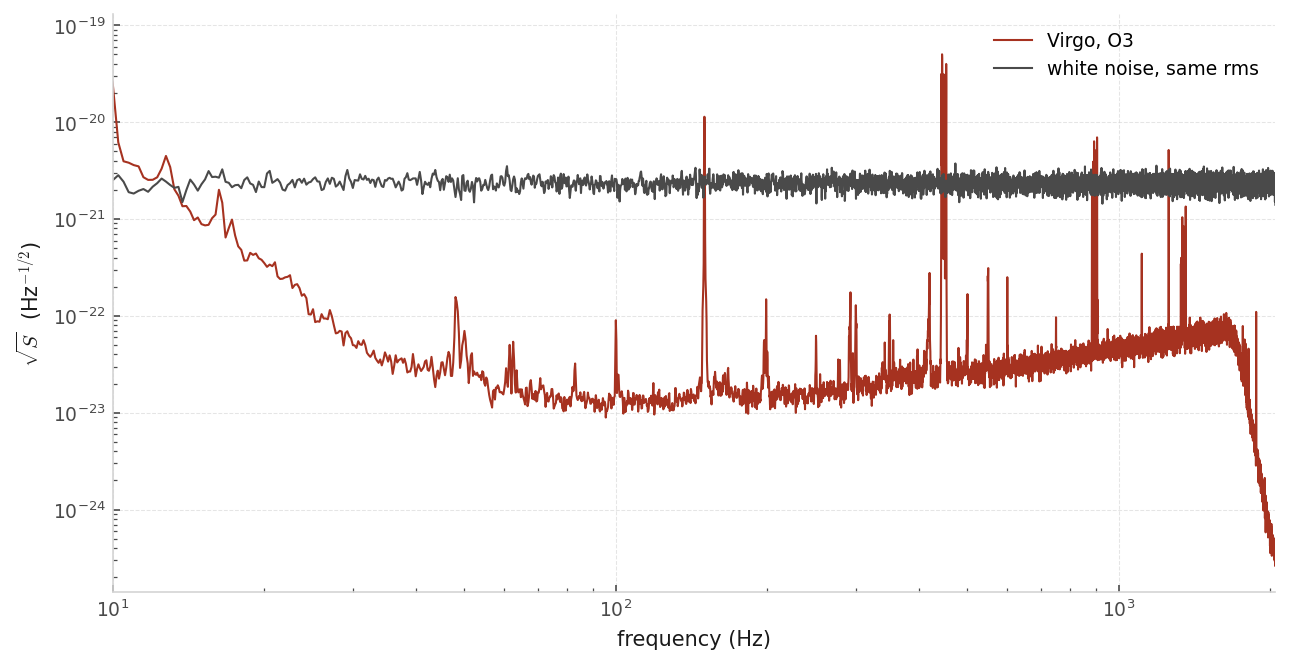

Virgo, median ASD from 10 to 20 Hz 1.15e-21, from 100 to 300 Hz 1.56e-23
10-20 Hz over 100-300 Hz: 74; white noise over 100-300 Hz: 151
white level from the rms: 2.39e-21


In [9]:
def draw_asd(curves, f_min_plot):
    """Draw amplitude spectral densities on log axes.

    Parameters
    ----------
    curves     : list of (freq, asd, label, color), one tuple for each curve
    f_min_plot : float, the lowest frequency drawn (Hz)
    """
    # one line for each curve, log axes, from f_min_plot to the Nyquist frequency
    fig, ax = plt.subplots(figsize=(10, 5))
    for freq, asd, label, color in curves:
        ax.loglog(freq[1:], asd[1:], color=color, lw=1.0, label=label)
    ax.set_xlim(f_min_plot, fs / 2)
    ax.set_xlabel('frequency (Hz)')
    ax.set_ylabel(r'$\sqrt{S}$  (Hz$^{-1/2}$)')
    ax.legend(frameon=False)
    plt.show()


# change these
seg_seconds = 4.0    # T_seg, the length of a segment (s)
f_min_plot = 10.0    # the lowest frequency drawn (Hz)

# white noise with the rms of the whole record
white_full = np.random.default_rng(7).normal(0.0, strain.std(), strain.size)

# the segment in samples, then Welch's method for the Virgo record and for white noise
nperseg = int(seg_seconds * fs)
freq, psd = signal.welch(strain, fs=fs, nperseg=nperseg, window='hann')
freq, psd_white = signal.welch(white_full, fs=fs, nperseg=nperseg, window='hann')
asd = np.sqrt(psd)
asd_white = np.sqrt(psd_white)

# the resolution and the number of segments
resolution = freq[1] - freq[0]
n_segments = int(2 * strain.size / nperseg) - 1
print(f"resolution {resolution:.3f} Hz, {n_segments} segments")
print(f"white noise: median ASD {np.median(asd_white):.2e}")
draw_asd([(freq, asd, 'Virgo, O3', P['BRICK']), (freq, asd_white, 'white noise, same rms', P['GREY_DARK'])], f_min_plot)

# the Virgo ASD in two bands, and how it compares with white noise
low = np.median(asd[(freq >= 10) & (freq < 20)])
bucket = np.median(asd[(freq >= 100) & (freq < 300)])
print(f"Virgo, median ASD from 10 to 20 Hz {low:.2e}, from 100 to 300 Hz {bucket:.2e}")
low_to_bucket = low / bucket
white_to_bucket = np.median(asd_white) / bucket
print(f"10-20 Hz over 100-300 Hz: {low_to_bucket:.0f}; white noise over 100-300 Hz: {white_to_bucket:.0f}")
# the check of the white level, sigma * sqrt(2 / fs)
white_level = strain.std() * np.sqrt(2 / fs)
print(f"white level from the rms: {white_level:.2e}")

**What to look at.**
- The white noise is a flat line, near $2.4\times10^{-21}\ \mathrm{Hz^{-1/2}}$.
- The Virgo curve crosses it twice. It is much higher at the left and much lower in the middle.
- The resolution is 0.25 Hz and there are 15 segments.
- Below 20 Hz the curve falls steeply with frequency. Narrow peaks stand out of the curve.

**What it shows.** The real noise is far from flat: it is about 70 times higher between 10 and 20 Hz than between 100 and 300 Hz. There it is about 150 times below the white noise of the same rms.

| quantity | value |
|---|---|
| resolution $1/T_{\mathrm{seg}}$ | 0.25 Hz |
| segments $K$ | 15 |
| white noise, ASD | $2.4\times10^{-21}\ \mathrm{Hz^{-1/2}}$ |
| Virgo, median between 10 and 20 Hz | $1.2\times10^{-21}\ \mathrm{Hz^{-1/2}}$ |
| Virgo, median between 100 and 300 Hz | $1.6\times10^{-23}\ \mathrm{Hz^{-1/2}}$ |

**Why.**
- White noise with an rms $\sigma$ has a flat ASD, $\sigma\sqrt{2/f_{s}}$. The check: $1.08\times10^{-19}\sqrt{2/4096} = 2.4\times10^{-21}$.
- The Virgo noise has the same total power and a very different shape. The power is moved to the left and to a few narrow lines. So in the middle of the band the noise is far below the white level. This is where the detector is most sensitive.
- This is the shape of the budget of lecture 11: a wall on the left, a floor, a slow rise on the right and lines. Step 4 puts the published curve on it.
- The ASD is what we compare with a signal: a strain per $\sqrt{\mathrm{Hz}}$. The record in time hides all this, as step 1 showed.

## Step 3 · The narrow lines

**What we do.** We search the ASD for narrow lines and we write down their frequencies. Then we ask what each one could be.

**The search.**
1. The continuum under the lines is a **running median** of the ASD over a window of 50 Hz: `signal.medfilt(asd, kernel)`. A narrow line is much narrower than the window and does not move the median. `kernel` is the number of bins and must be odd.
2. The **ratio** is the ASD divided by the continuum. A line is a peak of the ratio.
3. `signal.find_peaks(ratio, height=min_ratio)` returns the positions of the peaks of the ratio that are higher than `min_ratio`.

We start at 30 Hz because the wall at the left bends faster than the median can follow. We stop at 1700 Hz because the data fall steeply above that.

**The function.** `welch_asd` is step 2 in one call. `print_lines` prints a table of lines.

The parts of this step.

![The ASD, its running median, the ratio, the peaks above a threshold and a table of frequencies.](figures/h04class_task3_route.png)

In [10]:
def welch_asd(x, fs, seconds):
    """Return the one-sided amplitude spectral density by Welch's method, as in step 2.

    Parameters
    ----------
    x       : array, the record
    fs      : float, sampling frequency (Hz)
    seconds : float, the length of a segment (s)

    Returns
    -------
    (freq, asd) : freq the frequencies (Hz); asd the amplitude spectral density (Hz^-1/2)
    """
    # Hann window, 50 percent overlap, one sided; the ASD is the square root of the PSD
    freq, psd = signal.welch(x, fs=fs, nperseg=int(seconds * fs), window='hann')
    asd = np.sqrt(psd)
    curve = (freq, asd)
    return curve


def print_lines(freq, asd, ratio, peaks, n_lines):
    """Print the strongest lines as a table: frequency, ASD and ratio to the continuum.

    Parameters
    ----------
    freq, asd : arrays, the ASD (Hz and Hz^-1/2)
    ratio     : array, the ASD divided by the continuum
    peaks     : array of int, the positions of the lines
    n_lines   : int, how many lines to print
    """
    # the strongest first
    order = peaks[np.argsort(ratio[peaks])[::-1]]
    print("  f (Hz)    ASD (Hz^-1/2)    ratio")
    for i in order[:n_lines]:
        print(f"{freq[i]:8.2f}    {asd[i]:.2e}    {ratio[i]:7.1f}")


# change these
f_lo, f_hi = 30.0, 1700.0   # the band of the search (Hz)
floor_width = 50.0          # the width of the running median (Hz)
min_ratio = 5.0             # a line is a peak at least this many times the continuum
n_lines = 12                # how many lines to print

freq, asd = welch_asd(strain, fs, 4.0)

# keep the band of the search
band = (freq >= f_lo) & (freq <= f_hi)
f_b = freq[band]
a_b = asd[band]

# the continuum is a running median, the lines are the peaks of the ratio
kernel = int(floor_width / (f_b[1] - f_b[0])) | 1
floor = signal.medfilt(a_b, kernel)
ratio = a_b / floor
peaks, _ = signal.find_peaks(ratio, height=min_ratio)

print(f"{peaks.size} lines between {f_lo:.0f} and {f_hi:.0f} Hz with a ratio above {min_ratio}")
print_lines(f_b, a_b, ratio, peaks, n_lines)

# the strongest line in three bands: are the frequencies multiples of one another?
for lo, hi in ((440, 460), (880, 910), (1330, 1370)):
    in_band = (f_b >= lo) & (f_b <= hi)
    f_top = f_b[in_band][np.argmax(a_b[in_band])]
    print(f"strongest line between {lo} and {hi} Hz: {f_top:.2f} Hz")

# the harmonics of the violin modes: the strongest line of each group over the first one
f_first = 445.25
for f_line in (905.25, 1358.5, 1256.5):
    print(f"{f_line:.2f} Hz / {f_first:.2f} Hz = {f_line / f_first:.2f}")

44 lines between 30 and 1700 Hz with a ratio above 5.0
  f (Hz)    ASD (Hz^-1/2)    ratio
  445.25    5.02e-20     1905.6
  453.75    3.99e-20     1515.7
  444.00    3.15e-20     1193.8
  447.25    3.11e-20     1190.6
  449.50    3.09e-20     1177.5
  150.00    1.14e-20      723.5
  450.50    1.86e-20      708.1
  905.25    6.96e-21      148.0
  893.00    6.34e-21      137.8
  898.75    5.11e-21      110.8
  446.25    2.47e-21       94.1
 1256.50    5.16e-21       90.7
strongest line between 440 and 460 Hz: 445.25 Hz
strongest line between 880 and 910 Hz: 905.25 Hz
strongest line between 1330 and 1370 Hz: 1358.50 Hz
905.25 Hz / 445.25 Hz = 2.03
1358.50 Hz / 445.25 Hz = 3.05
1256.50 Hz / 445.25 Hz = 2.82


**What to look at.**
- 44 lines. The strongest twelve are seven lines between 444 and 454 Hz, three lines between 893 and 906 Hz, one at 150.00 Hz and one at 1256.50 Hz. They stand 90 to 1900 times above the continuum.
- Many more lines are weaker: the same search finds groups near 890 Hz and 1340 Hz.
- Change `f_hi` to 400: the lines below 400 Hz are 150.00 Hz, then five weak ones (100, 300, 48, 199 and 292.75 Hz). Lower `min_ratio` to 4 and more appear.

**What it shows.** The lines come in three families: multiples of 50 Hz, a group of violin modes near 450 Hz with its harmonics and a few lines for which this spectrum alone gives no name.

| frequency (Hz) | what it could be |
|---|---|
| 150.00 (and 100, 300) | multiples of 50 Hz: probably the mains. Virgo is in Europe, where the mains frequency is 50 Hz |
| 444 to 454, seven strong lines | the violin modes of the suspension fibers, probably. Each fiber is a string that rings at its own frequency, so there are several lines close together |
| 889 to 906 and 1337 to 1358 | the second and the third harmonic of the same violin modes, probably. The strongest lines of the three groups are at 445.25, 905.25 and 1358.5 Hz: the ratios are 2.03 and 3.05 |
| 48.00, 199.00, 292.75, 1256.50 | we cannot say. They are not multiples of 50 Hz and not violin modes. The frequency alone is not enough: the instrument keeps monitors that say where such a line comes from |

**Why.**
- The mains makes 50 Hz in the supply. Any small coupling to the instrument gives lines at 50 Hz and at its multiples. Here 150 Hz is the strongest and 100 and 300 Hz are weak. The line at 50 Hz itself is weak.
- A violin mode is the vibration of the fiber that holds the mirror, like a guitar string. A string has modes at $f_{1}$, $2f_{1}$, $3f_{1}$ and so on. This is why the three groups lie at about 1, 2 and 3 times 445 Hz. Lecture 11 gives the thermal noise of the fibers: it makes the modes ring. The modes show as lines.
- The violin lines carry 39 percent of the power of the record (step 1). They are very narrow, so they hide a small part of the band.
- The calibration lines are lines that the collaboration injects on purpose to measure the response of the detector. We have no list of their frequencies here. So we cannot say that any line of the table is one of them.
- The line at 1256.50 Hz is 2.8 times 445 Hz: not a harmonic of the violin modes. We do not know it.
- Lines are not in the budget of lecture 11: no model of five smooth noises predicts them.

## Step 4 · The data against the published curve

**What we do.** We put the measured ASD on the same axes as the published sensitivity curve of Advanced Virgo, O4. Then we add a flat line at the level of the shot noise, read from the plot. We find where the data are above the curve and which noise of lecture 11 sets the data there.

**Care.** The data are from the third run. The curve is a target of the fourth run. We compare the shapes and we expect an offset.

**The shot noise.** Lecture 11 gives a flat shot noise below the cavity pole, then a rise. We read from the plot the lowest value of the bucket and we draw it as a flat line.

**The function.** `draw_comparison` draws the data, the published curve and the flat line in the upper panel and the ratio of the data to the curve in the lower panel.

The parts of this step.

![The measured ASD and the published curve are drawn together with a flat line. The ratio of the data to the curve is computed at the frequencies of the data and printed in bands.](figures/h04class_task4_route.png)

   10 to    30 Hz: median of data / curve = 3.4
   30 to    60 Hz: median of data / curve = 2.8
   60 to   120 Hz: median of data / curve = 2.3
  120 to   300 Hz: median of data / curve = 3.2
  300 to  1000 Hz: median of data / curve = 5.4
 1000 to  1700 Hz: median of data / curve = 5.9


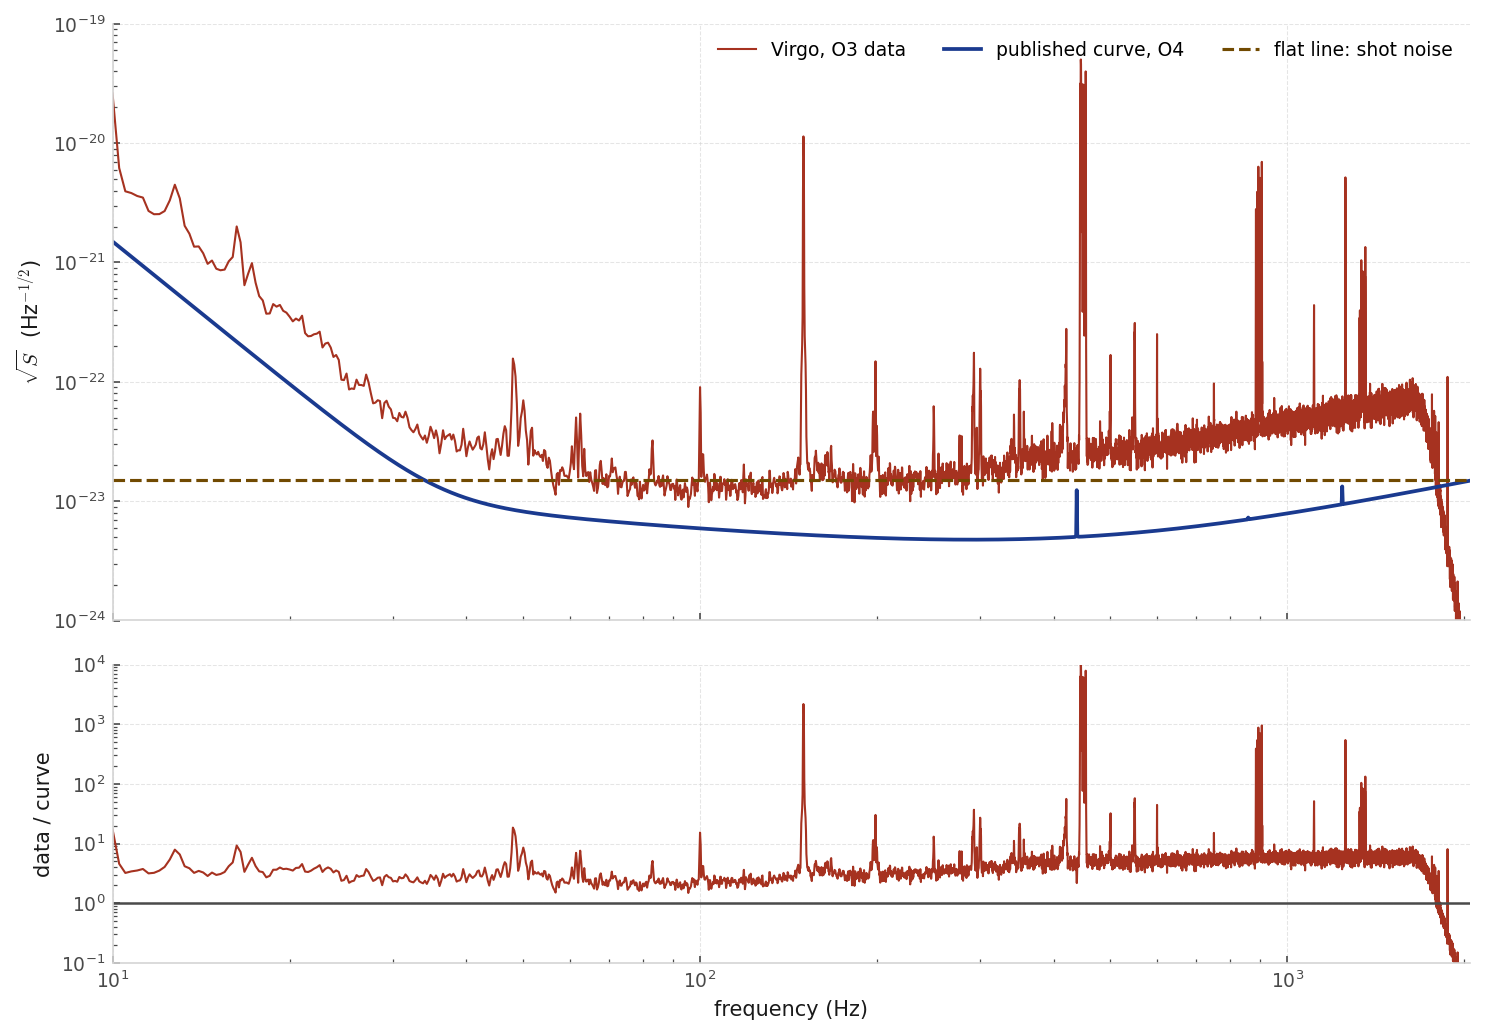

ASD at 12 Hz over ASD at 40 Hz: 107
1800 to 2048 Hz: median of data / curve = 0.12


In [11]:
def draw_comparison(freq, asd, design_f, design_asd, ratio, shot_level, f_min_plot):
    """Draw the data against the published curve and a flat line, with the ratio of the two.

    Parameters
    ----------
    freq, asd         : arrays, the measured ASD (Hz and Hz^-1/2)
    design_f, design_asd : arrays, the published curve
    ratio             : array, asd divided by the published curve at freq
    shot_level        : float, the level of the flat line (Hz^-1/2)
    f_min_plot        : float, the lowest frequency drawn (Hz)
    """
    # above: the three curves; below: the ratio, with a line at 1
    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    ax[0].loglog(freq[1:], asd[1:], color=P['BRICK'], lw=1.0, label='Virgo, O3 data')
    ax[0].loglog(design_f, design_asd, color=P['BLUE'], lw=1.8, label='published curve, O4')
    ax[0].axhline(shot_level, color=P['AMBER_DARK'], lw=1.5, ls='--', label='flat line: shot noise')
    ax[0].set_ylim(1e-24, 1e-19)
    ax[0].set_ylabel(r'$\sqrt{S}$  (Hz$^{-1/2}$)')
    ax[0].legend(frameon=False, ncol=3, loc='upper right')
    ax[1].loglog(freq[1:], ratio[1:], color=P['BRICK'], lw=1.0)
    ax[1].axhline(1.0, color=P['GREY_DARK'], lw=1.2)
    ax[1].set(xlim=(f_min_plot, fs / 2), ylim=(0.1, 1e4), xlabel='frequency (Hz)', ylabel='data / curve')
    plt.tight_layout()
    plt.show()


# change these
shot_level = 1.5e-23    # the flat line: the lowest value of the bucket, read from the plot (Hz^-1/2)
f_min_plot = 10.0       # the lowest frequency drawn (Hz)
bands = ((10, 30), (30, 60), (60, 120), (120, 300), (300, 1000), (1000, 1700))   # the bands of the table (Hz)

freq, asd = welch_asd(strain, fs, 4.0)
design = np.loadtxt(os.path.join(SENS, 'avirgo_O4.txt'))   # two columns: frequency (Hz) and ASD (Hz^-1/2)

# the published curve at the frequencies of the data, then the ratio of the data to it
design_on_freq = np.interp(freq, design[:, 0], design[:, 1])
ratio = asd / design_on_freq

# the median ratio in each band
for lo, hi in bands:
    in_band = (freq >= lo) & (freq < hi)
    print(f"{lo:5.0f} to {hi:5.0f} Hz: median of data / curve = {np.median(ratio[in_band]):.1f}")

draw_comparison(freq, asd, design[:, 0], design[:, 1], ratio, shot_level, f_min_plot)

# the wall: how much the data rise from 40 Hz to 12 Hz
wall = asd[np.argmin(np.abs(freq - 12))] / asd[np.argmin(np.abs(freq - 40))]
print(f"ASD at 12 Hz over ASD at 40 Hz: {wall:.0f}")
# above 1.8 kHz the data fall below the curve
top = (freq >= 1800) & (freq < 2048)
print(f"1800 to 2048 Hz: median of data / curve = {np.median(ratio[top]):.2f}")

**What to look at.**
- The data are above the curve everywhere between 10 Hz and 1.7 kHz. The median ratio is between 2.3 and 5.9.
- The ratio is smallest between 60 and 120 Hz and it grows above 300 Hz.
- The data touch the flat line from about 80 to 300 Hz and rise above it at higher frequencies.
- Above about 1.8 kHz the data fall below the curve.

**What it shows.** The data are two to six times above the published curve. Below 50 Hz the wall of the controls and the seismic noise sets them. The bucket is thermal and shot noise. At high frequency the shot noise rises.

| band | data / curve | what sets the data, probably |
|---|---|---|
| 10 to 30 Hz | 3.4 | the wall: seismic noise and the control noise |
| 30 to 60 Hz | 2.8 | the wall, ending |
| 60 to 120 Hz | 2.3 | the bucket: thermal noise of mirrors and suspensions, with shot noise |
| 120 to 300 Hz | 3.2 | the bucket: shot noise, with some thermal noise |
| 300 to 1000 Hz | 5.4 | shot noise, rising above the cavity pole |
| 1000 to 1700 Hz | 5.9 | shot noise, rising |

**Why.**
- The ratio is 2.3 to 5.9: the data of the third run are not as good as the curve of the fourth run. The shape is the same.
- On the left the data rise steeply, about a factor of 100 between 40 and 12 Hz, like the wall of lecture 11. In the measured budget of lecture 11 this is the controls, the environment and the seismic noise. We cannot separate them with one spectrum.
- Between about 80 and 300 Hz the data stay near the flat line, $1.5\times10^{-23}\ \mathrm{Hz^{-1/2}}$. The flat line is the shot noise below the cavity pole. In the measured budget the quantum noise is the largest above about 100 Hz. The thermal noise of the coatings is in the same place and is smaller there, probably. One spectrum cannot give the share of each: the budget needs models and monitors.
- Above 300 Hz the data rise above the flat line. This is the shot noise above the cavity pole: the arms respond less to the wave and the same photon noise counts more. The curve rises too.
- Above 1.8 kHz the data fall below the curve. A detector does not become quieter in this way. The file is sampled at 4096 Hz and its filter removes what is above about 1.8 kHz: probably an effect of the filter and not of the detector. So we do not use the data above 1.7 kHz.

## Step 5 · How long must the data be averaged?

**What we do.** We repeat step 2 with segments of 1 s, 4 s and 8 s. We look at two things. One is the scatter of the ASD where the noise is smooth. The other is the height of the line at 150 Hz.

**What we know.** The resolution is $1/T_{\mathrm{seg}}$. The scatter of the estimate falls as $1/\sqrt{K}$ with $K$ the number of segments. With 32 s of data we cannot have both a fine resolution and a small scatter. This was the bias and variance example of `H03`.

**The function.** `draw_segments` draws the three ASDs in two windows: a smooth band and the line.

The parts of this step.

![The same record is cut into segments of three lengths. For each, the ASD gives the scatter in a smooth band and the height of a line.](figures/h04class_task5_route.png)

  1 s: resolution 1.000 Hz, K = 63, median 4.86e-23, scatter  6.6 %, line 5.84e-21
  4 s: resolution 0.250 Hz, K = 15, median 4.80e-23, scatter 12.7 %, line 1.14e-20
  8 s: resolution 0.125 Hz, K =  7, median 4.76e-23, scatter 19.2 %, line 1.48e-20


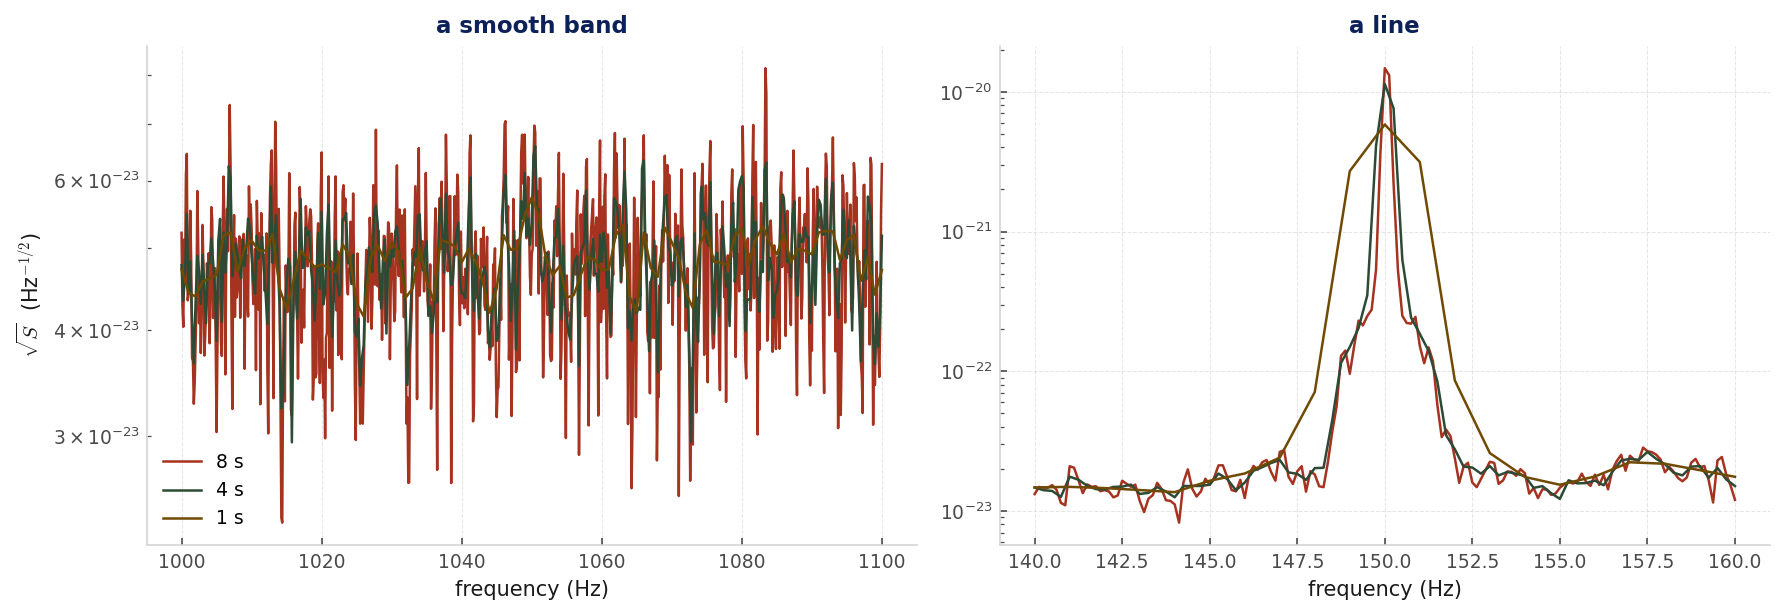

scatter grows by 2.9; sqrt(K_first / K_last) = 3.0
the line grows by 2.5; a perfect line would grow by 2.8


In [12]:
def draw_segments(results, smooth_band, line_band):
    """Draw the ASD for several segment lengths in a smooth band and around a line.

    Parameters
    ----------
    results     : list of (seconds, freq, asd), one tuple for each segment length
    smooth_band : (f_lo, f_hi), a band with no line (Hz)
    line_band   : (f_lo, f_hi), a band around one line (Hz)
    """
    # the same three curves in two windows of frequency
    colors = [P['AMBER_DARK'], P['SAGE_DARK'], P['BRICK']]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    # the longest segment first, so that the smoothest curve is drawn on top
    for (seconds, f, a), color in reversed(list(zip(results, colors))):
        for axis, (lo, hi) in zip(ax, (smooth_band, line_band)):
            in_band = (f >= lo) & (f <= hi)
            axis.semilogy(f[in_band], a[in_band], color=color, lw=1.2, label=f'{seconds:g} s')
    ax[0].set(xlabel='frequency (Hz)', ylabel=r'$\sqrt{S}$  (Hz$^{-1/2}$)', title='a smooth band')
    ax[1].set(xlabel='frequency (Hz)', title='a line')
    ax[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()


# change these
segment_seconds = (1.0, 4.0, 8.0)   # the lengths T_seg to try (s)
smooth_band = (1000.0, 1100.0)      # a band with no line (Hz)
line_band = (140.0, 160.0)          # a band around the line at 150 Hz (Hz)

# one ASD for each segment length
results = []
for seconds in segment_seconds:
    f, a = welch_asd(strain, fs, seconds)
    results.append((seconds, f, a))

# resolution, number of segments, the median and the scatter in the smooth band, the height of the line
for seconds, f, a in results:
    resolution = f[1] - f[0]
    n_segments = int(2 * 32 / seconds) - 1
    in_smooth = (f >= smooth_band[0]) & (f <= smooth_band[1])
    in_line = (f >= line_band[0]) & (f <= line_band[1])
    median = np.median(a[in_smooth])
    scatter = a[in_smooth].std() / a[in_smooth].mean()
    print(f"{seconds:3.0f} s: resolution {resolution:5.3f} Hz, K = {n_segments:2d}, median {median:.2e}, "
          f"scatter {100 * scatter:4.1f} %, line {a[in_line].max():.2e}")
draw_segments(results, smooth_band, line_band)

# the scatter against the number of segments, and the growth of the line
scatters, lines, counts = [], [], []
for seconds, f, a in results:
    in_smooth = (f >= smooth_band[0]) & (f <= smooth_band[1])
    in_line = (f >= line_band[0]) & (f <= line_band[1])
    scatters.append(a[in_smooth].std() / a[in_smooth].mean())
    lines.append(a[in_line].max())
    counts.append(int(2 * 32 / seconds) - 1)
scatter_growth = scatters[-1] / scatters[0]
expected_growth = np.sqrt(counts[0] / counts[-1])
line_growth = lines[-1] / lines[0]
perfect_line = np.sqrt(segment_seconds[-1] / segment_seconds[0])
print(f"scatter grows by {scatter_growth:.1f}; sqrt(K_first / K_last) = {expected_growth:.1f}")
print(f"the line grows by {line_growth:.1f}; a perfect line would grow by {perfect_line:.1f}")

**What to look at.**
- The median in the smooth band does not change with $T_{\mathrm{seg}}$.
- The scatter is about 7 percent for 1 s, 13 percent for 4 s and 19 percent for 8 s.
- The line at 150 Hz is the highest peak of the right window for every $T_{\mathrm{seg}}$. It is higher and narrower for longer segments.

**What it shows.** Short segments give a smooth curve and a coarse resolution. Long segments give a fine resolution and a noisy curve. A narrow line needs the long segments and the level of the noise needs the short ones.

| $T_{\mathrm{seg}}$ | resolution | $K$ | median in the smooth band | scatter | line at 150 Hz |
|---|---|---|---|---|---|
| 1 s | 1.000 Hz | 63 | $4.9\times10^{-23}$ | 6.6 % | $5.8\times10^{-21}$ |
| 4 s | 0.250 Hz | 15 | $4.8\times10^{-23}$ | 12.7 % | $1.1\times10^{-20}$ |
| 8 s | 0.125 Hz | 7 | $4.8\times10^{-23}$ | 19.2 % | $1.5\times10^{-20}$ |

**Why.**
- The level of a smooth noise does not depend on $T_{\mathrm{seg}}$. Only its scatter does.
- The scatter grows from 6.6 to 19.2 percent: a factor 2.9. The number of segments falls from 63 to 7: $\sqrt{63/7} = 3.0$. So the scatter goes as $1/\sqrt{K}$.
- A line is narrower than a bin. Its power goes into one bin of width $1/T_{\mathrm{seg}}$, so its density grows with $T_{\mathrm{seg}}$. For a perfect line the ASD would grow as $\sqrt{T_{\mathrm{seg}}}$: 2.8 from 1 s to 8 s. We find 2.5, because the line has a small width.
- With 32 s of data we choose. For the level of the noise we take 4 s or less. For a line we take 8 s or more. Longer data would let us have both. This is why the collaborations average hours of data.